# 

#	Operaciones de aprendizaje automático

Prof. Dr. Iván Reyes-Amezcua

A01732182 - Ing. Jose Luis Mendoza Mora 

# TC5061 Notebook Baseline

Exploracion del corpus SMS Spam Collection. La carga, la limpieza, el entrenamiento y el registro en MLflow estan en `src/`. Este notebook no entrena.

- Dataset: `data/raw/sms+spam+collection.zip`.
- Entorno: `.venv` de este proyecto.


In [ ]:
import csv
import io
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print(f"Python: {sys.version}")
print(f"pandas: {pd.__version__}")


## Paso 1. Carga y descripcion del dataset

El corpus trae un SMS por linea. Cada linea tiene dos columnas separadas por tabulador: la etiqueta (`ham` o `spam`) y el texto. No hay encabezado. La codificacion es Latin-1 y algunos mensajes incluyen comillas, asi que la lectura usa `quoting=csv.QUOTE_NONE`. Con el lector por defecto de pandas el archivo baja de 5,574 a 5,572 filas, porque dos mensajes se parten en las comillas.


In [ ]:
def find_raw_directory():
    candidates = [Path("data") / "raw", Path("..") / "data" / "raw"]
    for directory in candidates:
        if directory.exists():
            return directory
    raise FileNotFoundError("No esta data/raw.")

raw_directory = find_raw_directory()
extracted = raw_directory / "SMSSpamCollection"
archive = raw_directory / "sms+spam+collection.zip"
if extracted.exists():
    source = extracted
    encoding = "latin-1"
    data_path = extracted
elif archive.exists():
    with zipfile.ZipFile(archive) as zipped:
        text = zipped.read("SMSSpamCollection").decode("latin-1")
    source = io.StringIO(text)
    encoding = None
    data_path = archive
else:
    raise FileNotFoundError(raw_directory)

raw_df = pd.read_csv(
    source,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding=encoding,
    quoting=csv.QUOTE_NONE,
)
print("Ruta:", data_path.resolve())
print("Registros:", raw_df.shape[0])
print("Variables:", raw_df.shape[1])
print(raw_df.dtypes)
print(raw_df.head(3))
print(raw_df["label"].value_counts())
print("Nulos por columna:")
print(raw_df.isna().sum())
print("Filas duplicadas exactas:", int(raw_df.duplicated().sum()))


### Respuesta del paso 1

| Dato | Valor |
| --- | --- |
| Archivo | `SMSSpamCollection` (tab-separated, sin encabezado) |
| Registros | 5,574 |
| Variables | 2 |
| `label` | texto; `ham` = mensaje legitimo (4,827; 86.6%), `spam` = mensaje no deseado (747; 13.4%) |
| `message` | texto crudo del SMS en ingles |
| Tipos en pandas | ambas columnas son cadena (`str`) |
| Nulos | 0 en `label` y 0 en `message` |
| Duplicados exactos | 403 filas repetidas |

El problema es clasificacion binaria de texto. La clase spam es minoritaria, asi que la exactitud por si sola puede verse alta aunque el modelo ignore el spam.


## Paso 2. Analisis exploratorio

Se describen la longitud en caracteres y en palabras, el balance de clases y las palabras mas frecuentes de cada etiqueta. Estas cifras usan el archivo cargado, antes de quitar duplicados, para describir el corpus tal como llega.


       length    words
count  5574.0  5574.00
mean    80.57    15.59
std     59.91    11.39
min       2.0     1.00
25%      36.0     7.00
50%      62.0    12.00
75%     122.0    23.00
max     910.0   171.00
       length                                                    words         \
        count    mean    std   min    25%    50%    75%    max   count   mean   
label                                                                           
ham    4827.0   71.51  58.34   2.0   33.0   52.0   93.0  910.0  4827.0  14.30   
spam    747.0  139.08  28.98  13.0  133.0  149.0  157.0  224.0   747.0  23.91   

                                            
         std  min   25%   50%   75%    max  
label                                       
ham    11.50  1.0   7.0  11.0  19.0  171.0  
spam    5.78  2.0  22.0  25.0  28.0   35.0  


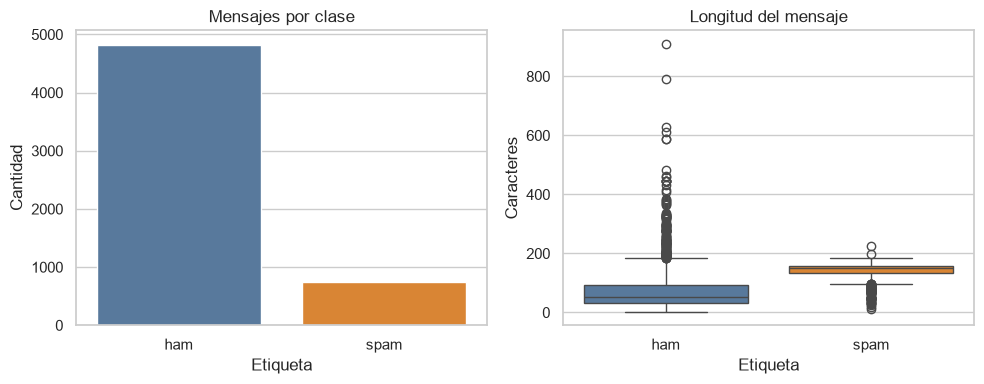

Palabras frecuentes en ham:
you     1948
the     1137
and      858
that     561
for      507
have     443
can      441
but      441
Name: count, dtype: int64
Palabras frecuentes en spam:
call    370
you     299
your    264
free    228
the     206
for     204
now     203
txt     170
Name: count, dtype: int64


In [3]:
eda_df = raw_df.copy()  # copia para no modificar la carga original
eda_df["message"] = eda_df["message"].astype("string").str.strip()  # texto comparable, sin espacios extremos
eda_df["length"] = eda_df["message"].str.len()  # caracteres de cada SMS
eda_df["words"] = eda_df["message"].str.split().str.len()  # tokens separados por espacio
print(eda_df[["length", "words"]].describe().round(2))  # estadisticos globales de longitud
print(eda_df.groupby("label")[["length", "words"]].describe().round(2))  # longitud separada por clase
sns.set_theme(style="whitegrid")  # estilo legible de las figuras
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # balance y longitud en la misma figura
sns.countplot(data=eda_df, x="label", hue="label", ax=axes[0], palette=["#4C78A8", "#F58518"], legend=False)  # conteo por clase
axes[0].set_title("Mensajes por clase")  # titulo del balance
axes[0].set_xlabel("Etiqueta")  # nombre del eje de clase
axes[0].set_ylabel("Cantidad")  # nombre del eje de conteo
sns.boxplot(data=eda_df, x="label", y="length", hue="label", ax=axes[1], palette=["#4C78A8", "#F58518"], legend=False)  # dispersion de la longitud
axes[1].set_title("Longitud del mensaje")  # titulo de la caja
axes[1].set_xlabel("Etiqueta")  # nombre del eje de clase
axes[1].set_ylabel("Caracteres")  # nombre del eje de longitud
fig.tight_layout()  # separa los dos paneles
plt.show()  # incrusta la figura en el notebook

def top_words(texts, n=8):  # cuenta palabras de al menos tres letras
    tokens = texts.str.lower().str.findall(r"[a-z]{3,}")  # pasa a minusculas y extrae palabras
    flat_words = [word for row in tokens for word in row]  # une las listas de cada mensaje
    return pd.Series(flat_words).value_counts().head(n)  # deja las n mas frecuentes

print("Palabras frecuentes en ham:")  # titulo del vocabulario legitimo
print(top_words(eda_df.loc[eda_df["label"] == "ham", "message"]))  # palabras tipicas de ham
print("Palabras frecuentes en spam:")  # titulo del vocabulario no deseado
print(top_words(eda_df.loc[eda_df["label"] == "spam", "message"]))  # palabras tipicas de spam


### Respuesta del paso 2

La longitud global tiene mediana de 62 caracteres y media de 80.57. El maximo es 910 caracteres y el minimo es 2.

| Clase | Media de caracteres | Mediana | Minimo | Maximo | Media de palabras |
| --- | --- | --- | --- | --- | --- |
| ham | 71.51 | 52 | 2 | 910 | 14.30 |
| spam | 139.08 | 149 | 13 | 224 | 23.91 |

El spam es mas largo y mas uniforme: casi todos los mensajes no deseados caen entre 13 y 224 caracteres, mientras el ham llega hasta 910 y se concentra en textos cortos. El grafico de barras muestra la mayoria ham (86.6%). El de cajas muestra esa diferencia de longitud.

En ham dominan palabras de conversacion (`you`, `the`, `and`, `that`). En spam aparecen `call`, `free`, `txt` y `your`, ademas de las mismas palabras funcionales. Esa diferencia de vocabulario justifica un modelo de bolsa de palabras como baseline: el texto, y no una variable numerica suelta, carga la senal de la clase.


## Paso 3. Limpieza

Se revisan faltantes, duplicados, tipos y valores extremos de longitud. Cada decision queda escrita debajo del codigo.


In [4]:
clean_df = raw_df.copy()  # trabaja sobre una copia de la carga
clean_df["message"] = clean_df["message"].astype("string").str.strip()  # fuerza texto y quita espacios extremos
clean_df["label"] = clean_df["label"].astype("string").str.strip().str.lower()  # fuerza etiqueta en minusculas
invalid_mask = clean_df["message"].eq("") | ~clean_df["label"].isin(["ham", "spam"])  # mensaje vacio o etiqueta ajena
print("Filas invalidas:", int(invalid_mask.sum()))  # en este corpus el resultado esperado es cero
clean_df = clean_df.loc[~invalid_mask].copy()  # se queda solo con filas validas
duplicates_after_strip = int(clean_df.duplicated(subset=["message"]).sum())  # copias extra del mismo texto
print("Duplicados de mensaje tras strip:", duplicates_after_strip)  # incluye los 403 originales y los que el strip igualo
clean_df = clean_df.drop_duplicates(subset=["message"], keep="first")  # conserva la primera copia de cada SMS
clean_df["length"] = clean_df["message"].str.len()  # longitud para la regla de atipicos
q1 = float(clean_df["length"].quantile(0.25))  # primer cuartil de la longitud
q3 = float(clean_df["length"].quantile(0.75))  # tercer cuartil de la longitud
iqr = q3 - q1  # rango intercuartil
low_bound = q1 - 1.5 * iqr  # valla inferior de Tukey
high_bound = q3 + 1.5 * iqr  # valla superior de Tukey
outlier_mask = (clean_df["length"] < low_bound) | (clean_df["length"] > high_bound)  # mensajes fuera de las vallas
print("Cuartiles e IQR:", q1, q3, iqr)  # parametros de la regla
print("Vallas:", low_bound, high_bound)  # limites numericos
print("Mensajes fuera de las vallas:", int(outlier_mask.sum()))  # se identifican y se conservan
print(clean_df.loc[outlier_mask, "label"].value_counts())  # clase de esos mensajes
print("Filas despues de limpiar:", len(clean_df))  # tamano de la tabla de modelado
print(clean_df["label"].value_counts())  # balance despues de quitar duplicados
print(clean_df.dtypes)  # tipos finales


Filas invalidas: 0
Duplicados de mensaje tras strip: 414
Cuartiles e IQR: 36.0 118.0 82.0
Vallas: -87.0 241.0
Mensajes fuera de las vallas: 65
label
ham    65
Name: count, dtype: int64[pyarrow]
Filas despues de limpiar: 5160
label
ham     4518
spam     642
Name: count, dtype: int64[pyarrow]
label      string
message    string
length      Int64
dtype: object


### Respuesta del paso 3. Decisiones

1. **Faltantes.** No hay nulos. Tampoco hay mensajes vacios ni etiquetas fuera de `ham` y `spam` despues de `strip` (0 filas invalidas). No se imputa nada.
2. **Tipos.** `label` y `message` ya llegan como texto. Se fuerzan a cadena, se recortan espacios y la etiqueta se pasa a minusculas para que `Spam` y `spam` no cuenten como clases distintas. La lectura con `QUOTE_NONE` evita perder 2 filas que el lector CSV por defecto parte por las comillas.
3. **Duplicados.** Hay 403 filas identicas en el archivo crudo. Despues de `strip`, 414 filas son copias extra del mismo texto: el recorte igualo 11 mensajes que antes diferian solo por espacios. Se eliminan esas copias y se conserva la primera. Quedan **5,160** mensajes: **4,518 ham (87.56%)** y **642 spam (12.44%)**. Un SMS repetido no aporta un caso nuevo y sesgaria la particion si la misma frase cayera en entrenamiento y en prueba.
4. **Atipicos.** Con la regla de Tukey sobre la longitud, Q1 = 36, Q3 = 118, IQR = 82, vallas = -87 y 241. Hay **65** mensajes por encima de 241 caracteres y todos son ham. La valla inferior es negativa, asi que ningun SMS corto queda marcado. Esos 65 textos largos son mensajes legitimos reales, y la longitud es parte de la senal (el spam es largo pero acotado; el ham extremo es todavia mas largo). **Se identifican y se conservan.** Borrarlos quitaria solo ham y acercaria las dos clases en una variable que el EDA mostro como informativa.


## Entrenamiento

El modelo ya no se ajusta en este notebook. El script `src/train.py` carga los datos, los limpia, entrena la regresion logistica sobre TF-IDF y registra cada corrida en MLflow.